# Probability, Naive Bayes and Outlier Removal

**Course:** CSCN8000 — Artificial Intelligence Algorithms and Mathematics
**Lab:** 2 — Spam Classification and Data Cleaning
**Name:** Nnamdi Ikengah
**Student ID:** 9085175

This lab has two parts:

- **Part A** trains Gaussian and Multinomial Naive Bayes classifiers to label emails as spam or ham, then compares them.
- **Part B** removes price outliers from the New York City Airbnb dataset using measures of central tendency and dispersion.

## Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay


---
# Part A — Spam Classification with Naive Bayes

## Concept: Naive Bayes

Naive Bayes applies **Bayes' theorem** to estimate the probability that an email is spam given the words it contains:

$$P(\text{spam} \mid \text{words}) = \frac{P(\text{words} \mid \text{spam}) \, P(\text{spam})}{P(\text{words})}$$

It is called *naive* because it assumes each word is independent of the others given the class. The two variants differ in how they model $P(\text{word} \mid \text{class})$:

| Classifier | Assumes each feature is… | Natural fit |
|---|---|---|
| **GaussianNB** | a continuous value drawn from a normal (bell-curve) distribution | measurements such as height or temperature |
| **MultinomialNB** | a count of how many times something occurs | word counts in text |

## A.1 Load the dataset

In [4]:
# A2: Load the email dataset
emails = pd.read_csv("Lab2_dataset.csv", index_col=0)
print(emails.shape)
emails.head()

(5171, 3)


     label                                               text  label_num
605    ham  Subject: enron methanol ; meter # : 988291\nth...          0
2349   ham  Subject: hpl nom for january 9 , 2001\n( see a...          0
3624   ham  Subject: neon retreat\nho ho ho , we ' re arou...          0
4685  spam  Subject: photoshop , windows , office . cheap ...          1
2030   ham  Subject: re : indian springs\nthis deal is to ...          0

**Interpretation:** The dataset has 5,171 emails and three columns. `label` is the class as text (ham or spam), `text` is the full email, and `label_num` is the same class as a number (0 = ham, 1 = spam). We will use `label_num` as the target for the models.

## A.2 Explore the data

label
ham     3672
spam    1499
Name: count, dtype: int64
Missing values: 0
Duplicate emails: 178


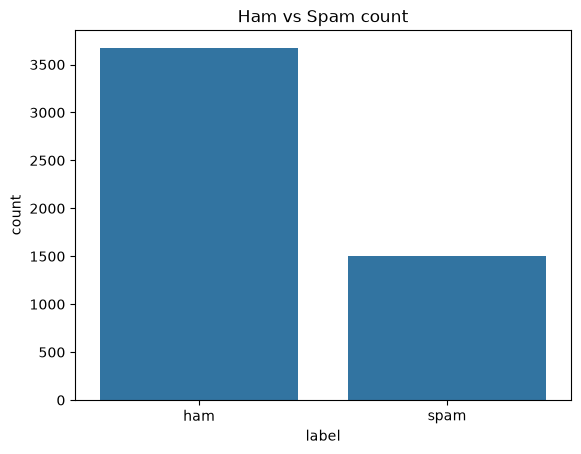

In [7]:
print(emails["label"].value_counts())
print("Missing values:", emails.isna().sum().sum())
print("Duplicate emails:", emails.duplicated(subset="text").sum())

sns.countplot(x="label", data=emails)
plt.title("Ham vs Spam count")
plt.show()


**Interpretation:** There are 3,672 ham emails and 1,499 spam emails, so about 71% of the data is ham. The classes are not balanced, which means accuracy alone could look better than it really is, so I also check precision and recall later. There are no missing values, but there are 178 duplicate emails. I remove those next so the same email can't end up in both the training and test sets.

## A.3 Remove duplicate emails

In [8]:
emails = emails.drop_duplicates(subset="text")
print(emails.shape)


(4993, 3)


## A.4 Split into train and test sets

In [9]:
X = emails['text']
y = emails['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## A.5 Convert text to numbers (bag of words)

Models cannot read text, so each email is turned into a vector of word counts with `CountVectorizer`.

In [10]:
vectorizer = CountVectorizer(stop_words="english", max_features=3000)
X_train_counts = vectorizer.fit_transform(X_train)
X_test_counts = vectorizer.transform(X_test)
print(X_train_counts.shape)


(3994, 3000)


- Use fit_transform on train and only transform on test, so no information from the test set leaks into training. The max_features=3000 cap is there because GaussianNB needs a dense matrix, and the full vocabulary would use gigabytes of RAM.

## A.6 Train the Gaussian Naive Bayes model

In [ ]:

gnb = GaussianNB()
gnb.fit(X_train_counts.toarray(), y_train)
gnb_pred = gnb.predict(X_test_counts.toarray())

print("GaussianNB accuracy:", accuracy_score(y_test, gnb_pred))
print(classification_report(y_test, gnb_pred, target_names=["ham", "spam"]))

GaussianNB accuracy: 0.9519519519519519
              precision    recall  f1-score   support

         ham       0.98      0.95      0.97       706
        spam       0.88      0.96      0.92       293

    accuracy                           0.95       999
   macro avg       0.93      0.96      0.94       999
weighted avg       0.95      0.95      0.95       999



**Interpretation:** GaussianNB got about 95.2% accuracy. It catches 96% of the spam emails (recall), but its spam precision is only 0.88. That means some real emails are being wrongly flagged as spam.

## A.7 Train the Multinomial Naive Bayes model

In [13]:
mnb = MultinomialNB()
mnb.fit(X_train_counts, y_train)
mnb_pred = mnb.predict(X_test_counts)

print("MultinomialNB accuracy:", accuracy_score(y_test, mnb_pred))
print(classification_report(y_test, mnb_pred, target_names=["ham", "spam"]))


MultinomialNB accuracy: 0.948948948948949
              precision    recall  f1-score   support

         ham       0.98      0.94      0.96       706
        spam       0.88      0.96      0.92       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999



**Interpretation:** MultinomialNB got about 94.9% accuracy, almost the same as GaussianNB. Its spam recall is also 0.96 and its spam precision is 0.88. With the same 3,000 words, the two models perform about the same.

## A.8 Compare the two models

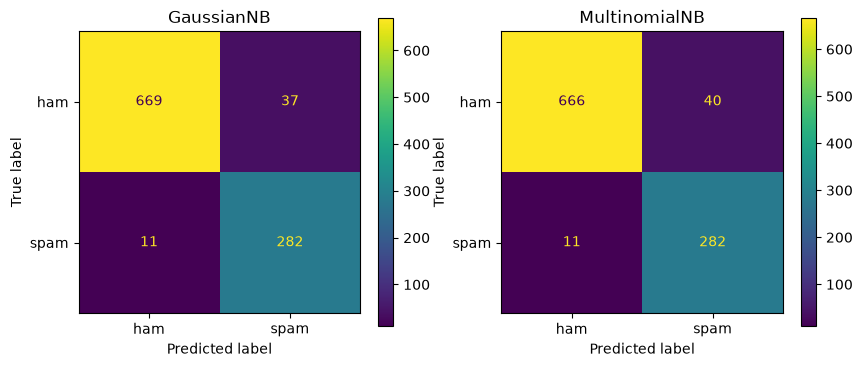

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, gnb_pred, display_labels=["ham", "spam"], ax=axes[0])
axes[0].set_title("GaussianNB")
ConfusionMatrixDisplay.from_predictions(y_test, mnb_pred, display_labels=["ham", "spam"], ax=axes[1])
axes[1].set_title("MultinomialNB")
plt.show()


**Interpretation:** The confusion matrices show the mistakes each model makes:

- **GaussianNB:** 37 ham emails wrongly marked as spam, and 11 spam emails missed.
- **MultinomialNB:** 40 ham emails wrongly marked as spam, and 11 spam emails missed.

Both models miss the same amount of spam. GaussianNB is slightly better here because it flags 3 fewer real emails as spam. The difference is very small though, so on these 3,000 features it's basically a tie.

## A.9 Multinomial NB with the full vocabulary

In [15]:
full_vectorizer = CountVectorizer(stop_words="english", min_df=2)
X_train_full = full_vectorizer.fit_transform(X_train)
X_test_full = full_vectorizer.transform(X_test)

mnb_full = MultinomialNB()
mnb_full.fit(X_train_full, y_train)
mnb_full_pred = mnb_full.predict(X_test_full)

print("Vocabulary size:", X_train_full.shape[1])
print("MultinomialNB (full vocab) accuracy:", accuracy_score(y_test, mnb_full_pred))
print(classification_report(y_test, mnb_full_pred, target_names=["ham", "spam"]))


Vocabulary size: 18543
MultinomialNB (full vocab) accuracy: 0.965965965965966
              precision    recall  f1-score   support

         ham       0.99      0.96      0.98       706
        spam       0.91      0.98      0.94       293

    accuracy                           0.97       999
   macro avg       0.95      0.97      0.96       999
weighted avg       0.97      0.97      0.97       999



**Interpretation:** When MultinomialNB uses the full vocabulary (18,543 words), accuracy goes up to about 96.6%, the best result in this lab. It now wrongly flags only 28 ham emails and misses just 6 spam emails. Spam recall went up to 0.98 and spam precision to 0.91.

GaussianNB can't do this. It needs the data as a dense matrix, and with 18,000+ words that would take too much memory. MultinomialNB works with sparse word counts, so it can use all the words easily.

## A.10 Predictions on test data

In [17]:
sample = X_test.sample(5, random_state=1)
sample_pred = mnb_full.predict(full_vectorizer.transform(sample))

results = pd.DataFrame({
    "email_start": sample.str[:80],
    "actual": y_test.loc[sample.index].map({0: "ham", 1: "spam"}),
    "predicted": pd.Series(sample_pred, index=sample.index).map({0: "ham", 1: "spam"}),
})
results


                                            email_start actual predicted
4361  Subject: sex that hurts - stretch till they sq...   spam      spam
317   Subject: 98 - 6892 overflow\ncan you please ex...    ham       ham
4273  Subject: shape your wood .\nclick here to orde...   spam      spam
3677  Subject: emerging small cap\nto exit all addit...   spam      spam
3204  Subject: eastrans nomination change effective ...    ham       ham

In [18]:
my_emails = [
    "Subject: congratulations you won a free prize click here now",
    "Subject: meeting moved to 3pm , please update the gas volume sheet",
]
predictions = mnb_full.predict(full_vectorizer.transform(my_emails))
for text, p in zip(my_emails, predictions):
    print("SPAM" if p == 1 else "HAM ", "|", text)


SPAM | Subject: congratulations you won a free prize click here now
HAM  | Subject: meeting moved to 3pm , please update the gas volume sheet


**Interpretation:** I used the best model (MultinomialNB with the full vocabulary) to predict 5 random emails from the test set, and it got all 5 right. I also tested two emails I wrote myself. The "you won a free prize, click here" email was predicted as spam, and the work email about a meeting and the gas volume sheet was predicted as ham. That's what we would expect, so the model seems to have learned which words are typical of spam.

## Part A Conclusion

**MultinomialNB is the better model for this task.**

- With the same 3,000 words, both models were almost tied (GaussianNB 95.2%, MultinomialNB 94.9%).
- With the full vocabulary, MultinomialNB reached **96.6% accuracy**, with spam recall of 0.98 and spam precision of 0.91. It only missed 6 spam emails out of 293.
- GaussianNB couldn't be trained on the full vocabulary because of memory limits.

MultinomialNB makes more sense for text because it is built for count data, like how many times each word appears in an email. GaussianNB assumes each feature follows a normal (bell-shaped) distribution, which doesn't really fit word counts, since most words appear 0 times in most emails.

---
# Part B — Removing Price Outliers from NYC Airbnb Data

## Concept: Outliers, central tendency and dispersion

An **outlier** is a value far from the rest of the data. Outliers pull the **mean** towards them, while the **median** barely moves. That makes the mean and the median a quick test for skew.

This part compares four ways to remove outliers:

1. **Z-score**, which uses the mean and standard deviation.
2. **IQR (Tukey's fences)**, which uses the quartiles.
3. **Percentile trimming**, which cuts the top and bottom 1%.
4. **IQR per room type**, which applies the same IQR rule separately to each room type.

## B.1 Load the dataset

In [ ]:

airbnb = pd.read_csv("AB_NYC_2019.csv")
print(airbnb.shape)
airbnb[["name", "neighbourhood_group", "room_type", "price"]].head()


(48895, 16)


                                               name neighbourhood_group  \
0                Clean & quiet apt home by the park            Brooklyn   
1                             Skylit Midtown Castle           Manhattan   
2               THE VILLAGE OF HARLEM....NEW YORK !           Manhattan   
3                   Cozy Entire Floor of Brownstone            Brooklyn   
4  Entire Apt: Spacious Studio/Loft by central park           Manhattan   

         room_type  price  
0     Private room    149  
1  Entire home/apt    225  
2     Private room    150  
3  Entire home/apt     89  
4  Entire home/apt     80  

## B.2 Summary statistics: mean vs median

In [ ]:

print(airbnb["price"].describe())
print("Mean:  ", airbnb["price"].mean())
print("Median:", airbnb["price"].median())
print("Skewness:", airbnb["price"].skew())
print("Listings priced at $0:", (airbnb["price"] == 0).sum())


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64
Mean:   152.7206871868289
Median: 106.0
Skewness: 19.118938995046033
Listings priced at $0: 11


**Interpretation:** The mean price is about \$153, but the median is only \$106. The mean is much higher because a few very expensive listings pull it up. The maximum price is \$10,000, while 75% of listings cost \$175 or less. The skewness of about 19 confirms the data is heavily right-skewed. There are also 11 listings with a price of \$0, which doesn't make sense for a real rental, so those are bad data.

## B.3 Visualise the raw price distribution

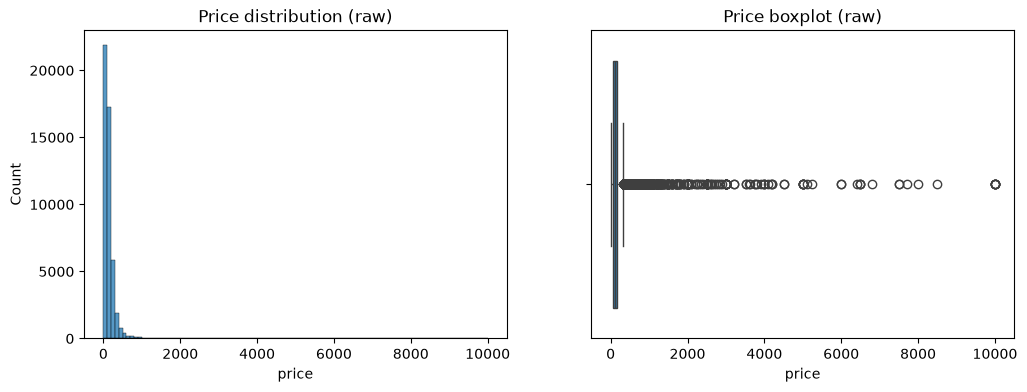

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(airbnb["price"], bins=100, ax=axes[0])
axes[0].set_title("Price distribution (raw)")
sns.boxplot(x=airbnb["price"], ax=axes[1])
axes[1].set_title("Price boxplot (raw)")
plt.show()


**Interpretation:** The histogram is squashed against the left side because almost all prices are low, with a long thin tail stretching out to \$10,000. In the boxplot, the box itself is tiny and there are lots of points far to the right of it. Those points are the outliers. This shows clearly that the data needs cleaning before it can be used.

## B.4 Remove invalid $0 prices

In [ ]:

prices = airbnb[airbnb["price"] > 0].copy()
print(len(airbnb) - len(prices), "zero-price rows removed")


11 zero-price rows removed


## B.5 Method 1 — Z-score (mean and standard deviation)

$$z = \frac{x - \mu}{\sigma}$$

Any listing with $|z| > 3$ is treated as an outlier.

In [ ]:

mean = prices["price"].mean()
std = prices["price"].std()
z_scores = (prices["price"] - mean) / std

z_clean = prices[z_scores.abs() <= 3]
print(f"Upper limit: ${mean + 3 * std:.2f}")
print("Rows removed:", len(prices) - len(z_clean))


Upper limit: $873.27
Rows removed: 388


**Interpretation:** The z-score method removed 388 listings and set the upper limit at about \$873. This limit is quite high because the outliers themselves pushed the mean and standard deviation up, so the method is too lenient. It also assumes the data is normally distributed, and these prices are heavily skewed, so z-score isn't the best fit here.

## B.6 Method 2 — IQR (interquartile range)

$$IQR = Q3 - Q1, \quad \text{keep } Q1 - 1.5 \times IQR \le x \le Q3 + 1.5 \times IQR$$

In [24]:
q1 = prices["price"].quantile(0.25)
q3 = prices["price"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

iqr_clean = prices[prices["price"].between(lower, upper)]
print(f"Q1={q1}, Q3={q3}, IQR={iqr}")
print(f"Limits: {lower} to {upper}")
print("Rows removed:", len(prices) - len(iqr_clean))


Q1=69.0, Q3=175.0, IQR=106.0
Limits: -90.0 to 334.0
Rows removed: 2972


**Interpretation:** The IQR method uses the quartiles: Q1 = \$69, Q3 = \$175, so IQR = \$106. Anything above \$334 is treated as an outlier, and 2,972 listings were removed. The lower limit came out negative (-\$90), so it doesn't remove any cheap listings. Quartiles aren't affected much by extreme values, which makes this method more reliable than z-score for skewed data like this.

## B.7 Method 3 — Percentile trimming (1st to 99th)

In [26]:

p01 = prices["price"].quantile(0.01)
p99 = prices["price"].quantile(0.99)

pct_clean = prices[prices["price"].between(p01, p99)]
print(f"Keeping ${p01} to ${p99}")
print("Rows removed:", len(prices) - len(pct_clean))


Keeping $30.0 to $799.0
Rows removed: 867


**Interpretation:** Percentile trimming keeps only prices between the 1st and 99th percentiles (\$30 to \$799), which removed 867 listings. It's simple, and it cuts both very cheap and very expensive listings. The downside is that it always removes 2% of the data, whether those values are real outliers or not.

## B.8 Method 4 — IQR per room type

In [27]:
prices.groupby("room_type")["price"].quantile([0.25, 0.75]).unstack()


                  0.25   0.75
room_type                    
Entire home/apt  120.0  229.0
Private room      50.0   95.0
Shared room       33.0   75.0

In [28]:
room_q1 = prices.groupby("room_type")["price"].transform("quantile", 0.25)
room_q3 = prices.groupby("room_type")["price"].transform("quantile", 0.75)
room_iqr = room_q3 - room_q1

room_clean = prices[
    (prices["price"] >= room_q1 - 1.5 * room_iqr) &
    (prices["price"] <= room_q3 + 1.5 * room_iqr)
]
print("Rows removed:", len(prices) - len(room_clean))
room_clean.groupby("room_type")["price"].agg(["min", "max", "count"])


Rows removed: 3244


                 min  max  count
room_type                       
Entire home/apt   10  392  23536
Private room      10  160  21029
Shared room       10  130   1075

**Interpretation:** The quartiles are very different for each room type. A typical entire home costs \$120 to \$229, but a shared room is only \$33 to \$75. So a \$300 shared room is clearly an outlier, while a \$300 entire apartment is pretty normal. Applying IQR separately to each room type gives each one its own fair limits: about \$392 for entire homes, \$160 for private rooms and \$130 for shared rooms. This removed 3,244 listings in total.

## B.9 Compare all methods

In [29]:
methods = {
    "Original (no $0)": prices,
    "Z-score": z_clean,
    "IQR": iqr_clean,
    "Percentile 1-99": pct_clean,
    "IQR per room type": room_clean,
}

summary = pd.DataFrame({
    name: {
        "rows": len(d),
        "removed": len(prices) - len(d),
        "mean": d["price"].mean(),
        "median": d["price"].median(),
        "std": d["price"].std(),
        "max": d["price"].max(),
        "skew": d["price"].skew(),
    }
    for name, d in methods.items()
}).T.round(2)
summary


                      rows  removed    mean  median     std      max   skew
Original (no $0)   48884.0      0.0  152.76   106.0  240.17  10000.0  19.12
Z-score            48496.0    388.0  138.78   105.0  107.55    860.0   2.45
IQR                45912.0   2972.0  120.00   100.0   68.13    334.0   0.92
Percentile 1-99    48017.0    867.0  138.50   105.0  103.69    799.0   2.28
IQR per room type  45640.0   3244.0  121.81   100.0   73.23    392.0   1.17

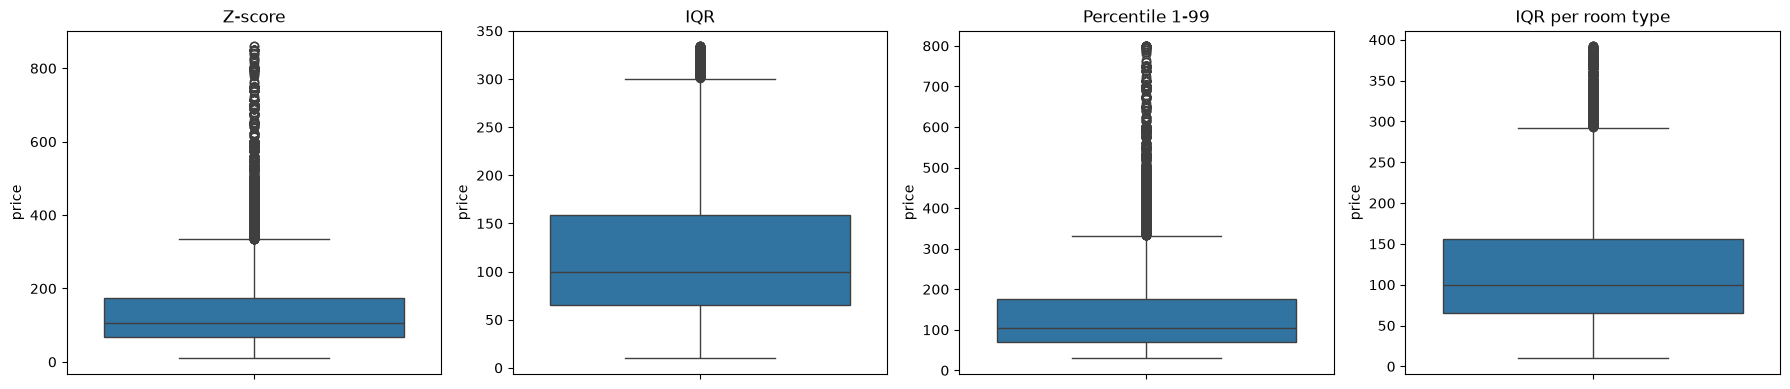

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, d) in zip(axes, list(methods.items())[1:]):
    sns.boxplot(y=d["price"], ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()


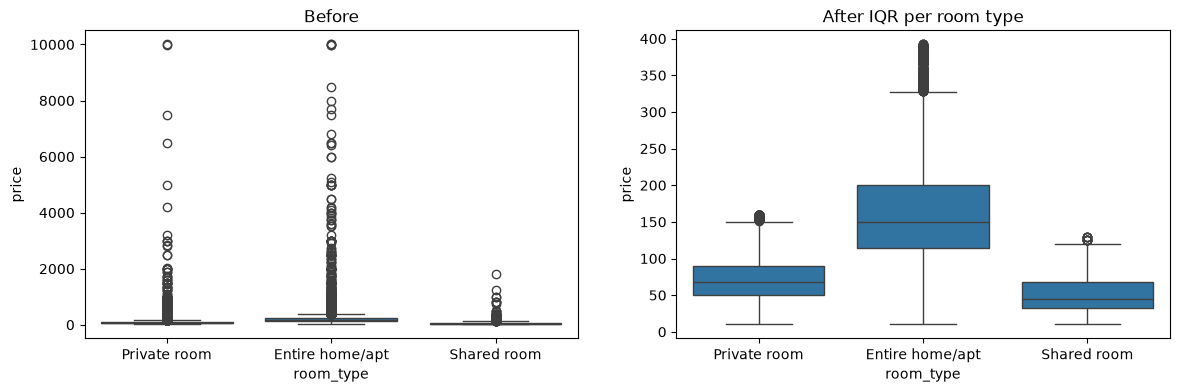

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=prices, x="room_type", y="price", ax=axes[0])
axes[0].set_title("Before")
sns.boxplot(data=room_clean, x="room_type", y="price", ax=axes[1])
axes[1].set_title("After IQR per room type")
plt.show()


**Interpretation:** The summary table shows that as outliers are removed, the **mean moves closer to the median**. The original mean was \$153, and after IQR cleaning it dropped to about \$120. The **median barely changes** (\$106 down to \$100), which shows the median isn't affected much by outliers but the mean is.

Skewness also drops a lot, from 19 down to around 1 for both IQR methods. Z-score and percentile trimming still leave a skew of over 2 and keep prices up to \$800 or more. In the room type boxplots, the "before" chart is dominated by extreme points, while the "after" chart shows a clear and realistic price range for each room type.

## B.10 Save the clean dataset

In [32]:
room_clean.to_csv("AB_NYC_2019_clean.csv", index=False)
print("Saved", len(room_clean), "rows")


Saved 45640 rows


## Part B Conclusion

**I chose IQR per room type for the final clean dataset.**

- **Z-score** was the weakest. The outliers inflated the mean and standard deviation, so the limit (\$873) was too high, and it assumes the data is normal when it's actually very skewed.
- **Percentile trimming** is easy, but it always removes a fixed 2% no matter what the data looks like.
- **Plain IQR** worked well and brought skew down to 0.92, but it uses one limit for every listing. That's unfair, because entire homes are naturally more expensive than shared rooms.
- **IQR per room type** gives each room type its own limits, so it compares each listing with similar listings. It brought the skew down to 1.17 and left a realistic price range for each type.

The final clean dataset has **45,640 listings** and is saved as `AB_NYC_2019_clean.csv`.